# Final auricular dataset + canine measurements

68 individuals, 111 expected observed masks. Metadata sorted numerically, including 48.2. The database includes 16 canine measurement fields for everyone; blanks are unknown/not recorded, never zero or inferred tooth absence. Measurements transcribed from the supplied non-adult screenshot; screenshot units are not specified, so no physical unit is asserted. UL/UR/DL/DR labels are retained verbatim. 71 and 173 have identical displayed measurements: verify the source. Individual 7 and all adult-test rows have no masks in the provided file list and are not in the final cohort.

Original metadata and full non-adult transcription are in archive/. No sex prediction is performed. Sex codes are register entries, not independently verified labels. Shape and dental data are separate modalities; dental availability does not control inclusion in shape PCA.

Install requirements.txt, copy actual PNGs into masks/, open notebook in the project folder. Originals are never changed. Rotation alone is not reflection. This replaces the prior notebook and includes the white-background threshold fix.

In [1]:
from pathlib import Path
import re,json,hashlib,platform,importlib.metadata as version
import numpy as np
import pandas as pd
from PIL import Image
from scipy import ndimage
from skimage.measure import find_contours
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from pyefd import elliptic_fourier_descriptors,normalize_efd,reconstruct_contour
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
OUTPUT=ROOT/'analysis_output'
MASK_DIR=ROOT/'masks'
RIGHT_ALREADY_REFLECTED=False
BACKGROUND_TOLERANCE=20
N_POINTS=512
HARMONICS=12
SEED=42
APPROVED_REVIEW_FILENAMES=[]
for sub in ['normalized_masks','reconstruction_qc']:(OUTPUT/sub).mkdir(parents=True,exist_ok=True)
metadata=pd.read_csv(ROOT/'consolidated_metadata.csv',dtype=str,keep_default_na=False)
metadata=metadata.sort_values('individual_id',key=lambda s:pd.to_numeric(s))
expected=pd.read_csv(ROOT/'expected_mask_manifest.csv',dtype=str,keep_default_na=False)
assert metadata.individual_id.is_unique and len(metadata)==68
DENTAL=[c for c in metadata if re.match(r'^canine_(ul|ur|dl|dr)_',c)]
metadata[DENTAL]=metadata[DENTAL].apply(pd.to_numeric,errors='coerce')
assert len(DENTAL)==16
display(metadata.head())


,individual_id,context_number,box_number,number_of_boxes,sex_code,age_original,age_group,preservation,skeleton_completeness_percent,sides_available,...,canine_dl_bl_cervical,canine_dl_md_crown,canine_dl_md_cervical,canine_dr_bl_crown,canine_dr_bl_cervical,canine_dr_md_crown,canine_dr_md_cervical,canine_measurement_count,canine_source,canine_review_note
0,8,1015,29,1,S,5-6,juvenile,G,60,LR,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,,
1,9,1017,28,1,S,0.5-1.5,infant,E,95,LR,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,,
2,11,1013,27,1,S,40W,newborn,G,90,L,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,,
3,12,1023,30,1,S,5-6,juvenile,E,85,L,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,,
4,16,1027,30,1,S,4.5-5.5,juvenile,M,70,LR,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,,


## Inventory
Filename labels govern reflection; they are not independently verified anatomical labels. All seven original side discrepancies are preserved in the archived metadata. 305 in particular was L in the earlier inventory but R in the filenames. No missing side is fabricated for statistical analysis.

In [2]:
pattern=re.compile(r'^(?:f)?(?P<id>\d+(?:[.,-]\d+)?)[_ ]?(?P<side>[LR])(?:[^A-Za-z].*)?$',re.I)
rows=[]
for p in sorted(MASK_DIR.rglob('*')):
    if p.suffix.lower() not in {'.png','.jpg','.jpeg','.tif','.tiff','.bmp'}:continue
    m=pattern.match(p.stem)
    rows.append({'filename':p.name,'path':str(p),'individual_id':m['id'].replace('-','.').replace(',','.') if m else '', 'side':m['side'].upper() if m else '', 'parsed':bool(m),'sha256':hashlib.sha256(p.read_bytes()).hexdigest()})
assert rows,'Place actual images in masks/ before running'
inventory=pd.DataFrame(rows)
inventory['duplicate_side']=inventory.parsed & inventory.duplicated(['individual_id','side'],keep=False)
inventory['duplicate_content']=inventory.duplicated('sha256',keep=False)
inventory['in_metadata']=inventory.individual_id.isin(metadata.individual_id)
actual=set(zip(inventory.loc[inventory.parsed,'individual_id'],inventory.loc[inventory.parsed,'side']))
wanted=set(zip(expected.individual_id,expected.side))
inventory.to_csv(OUTPUT/'file_inventory.csv',index=False)
pd.DataFrame(sorted(wanted-actual),columns=['individual_id','side']).to_csv(OUTPUT/'missing_masks.csv',index=False)
pd.DataFrame(sorted(actual-wanted),columns=['individual_id','side']).to_csv(OUTPUT/'unexpected_masks.csv',index=False)
display(pd.Series({'files':len(inventory),'missing':len(wanted-actual),'unexpected':len(actual-wanted)}))
display(inventory[~inventory.parsed | inventory.duplicate_side | inventory.duplicate_content])


files         111
missing         0
unexpected      0
dtype: int64

,filename,path,individual_id,side,parsed,sha256,duplicate_side,duplicate_content,in_metadata


## Extract silhouettes including light-grey/transparent paint
Composite on white and select pixels at least BACKGROUND_TOLERANCE darker than white. Largest component retained and holes filled; changes logged. Original pixel scale retained in saved working masks; descriptors are scale-normalized. Check edge halos and threshold sensitivity. No smoothing applied. Border contact is flagged, not silently repaired.

In [3]:
def extract(path,flip=False):
    with Image.open(path) as im:
        rgba=im.convert('RGBA')
        gray=np.asarray(Image.alpha_composite(Image.new('RGBA',rgba.size,'white'),rgba).convert('L'))
    binary=gray.astype(np.int16)<255-BACKGROUND_TOLERANCE
    if not binary.any():raise ValueError('No foreground')
    border=bool(binary[0].any() or binary[-1].any() or binary[:,0].any() or binary[:,-1].any())
    labels,n=ndimage.label(binary);counts=np.bincount(labels.ravel());counts[0]=0
    largest=labels==counts.argmax();discarded=float(1-largest.sum()/binary.sum())
    filled=ndimage.binary_fill_holes(largest);holes=int(filled.sum()-largest.sum())
    if flip:filled=np.fliplr(filled)
    y,x=np.where(filled);crop=filled[y.min():y.max()+1,x.min():x.max()+1]
    mask=np.pad(crop,max(5,int(.05*max(crop.shape))))
    curve=max(find_contours(mask.astype(float),.5),key=len)[:,::-1]
    curve=np.vstack([curve,curve[0]])
    d=np.r_[0,np.cumsum(np.linalg.norm(np.diff(curve,axis=0),axis=1))]
    unique=np.r_[True,np.diff(d)>0];d=d[unique];curve=curve[unique]
    t=np.linspace(0,d[-1],N_POINTS,endpoint=False)
    pts=np.column_stack([np.interp(t,d,curve[:,j]) for j in [0,1]])
    signed=np.sum(pts[:,0]*np.roll(pts[:,1],-1)-np.roll(pts[:,0],-1)*pts[:,1])
    if signed<0:pts=pts[::-1]
    pts=np.vstack([pts,pts[0]])
    stats={'area_px2':int(filled.sum()),'perimeter_px':float(d[-1]),'touches_border':border,'discarded_fraction':discarded,'filled_hole_pixels':holes,'low_resolution':min(crop.shape)<80,'flipped_to_left':flip}
    return mask,pts,stats

qc=[];records=[];cache={}
for r in inventory.itertuples():
    row={'individual_id':r.individual_id,'side':r.side,'filename':r.filename,'status':'excluded','reason':''}
    if not r.parsed or r.duplicate_side:
        row['reason']='Unparsed filename or duplicate individual-side';qc.append(row);continue
    try:
        mask,pts,stats=extract(r.path,r.side=='R' and not RIGHT_ALREADY_REFLECTED)
        raw=elliptic_fourier_descriptors(pts,order=HARMONICS,normalize=False)
        coeff=normalize_efd(raw.copy())
        if not np.isfinite(coeff).all():raise ValueError('Nonfinite Fourier coefficients')
        key=f'{r.individual_id}_{r.side}';cache[key]=(mask,pts,raw)
        Image.fromarray(np.where(mask,0,255).astype('uint8')).save(OUTPUT/'normalized_masks'/f'{key}.png')
        flagged=stats['touches_border'] or stats['discarded_fraction']>.01 or stats['low_resolution'] or r.duplicate_content or not r.in_metadata
        row.update(stats,status='review' if flagged else 'ok')
        records.append({'individual_id':r.individual_id,'side':r.side,'filename':r.filename,**{f'efd_{i:03d}':float(v) for i,v in enumerate(coeff.ravel())}})
    except Exception as e:row['reason']=str(e)
    qc.append(row)
qc=pd.DataFrame(qc);qc.to_csv(OUTPUT/'mask_qc.csv',index=False)
descriptors=pd.DataFrame(records);assert len(descriptors),'No usable masks'
descriptors.to_csv(OUTPUT/'observed_side_descriptors.csv',index=False)
display(qc.groupby('status').size());display(qc[qc.status!='ok'])


status
ok        36
review    75
dtype: int64

,individual_id,side,filename,status,reason,area_px2,perimeter_px,touches_border,discarded_fraction,filled_hole_pixels,low_resolution,flipped_to_left
0,108,L,f108L.png,review,,119331,2166.140403,True,0.000000,2,False,False
3,114,R,f114R.png,review,,34037,1116.087445,True,0.000029,0,False,True
5,118,R,f118R.png,review,,140033,3253.232898,True,0.000000,1,False,True
7,122,L,f122L.png,review,,28125,927.116882,True,0.000000,4,False,False
9,128,L,f128L.png,review,,71422,1506.822510,True,0.000000,2,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...
100,85,R,f85R.png,review,,265576,3142.865366,True,0.000000,2,False,True
104,93,R,f93R.png,review,,216599,2626.986074,True,0.000023,0,False,True
105,95,L,f95L.png,review,,40780,1299.023520,True,0.000000,1,False,False
108,97,R,f97R.png,review,,173856,2576.549565,True,0.000000,0,False,True


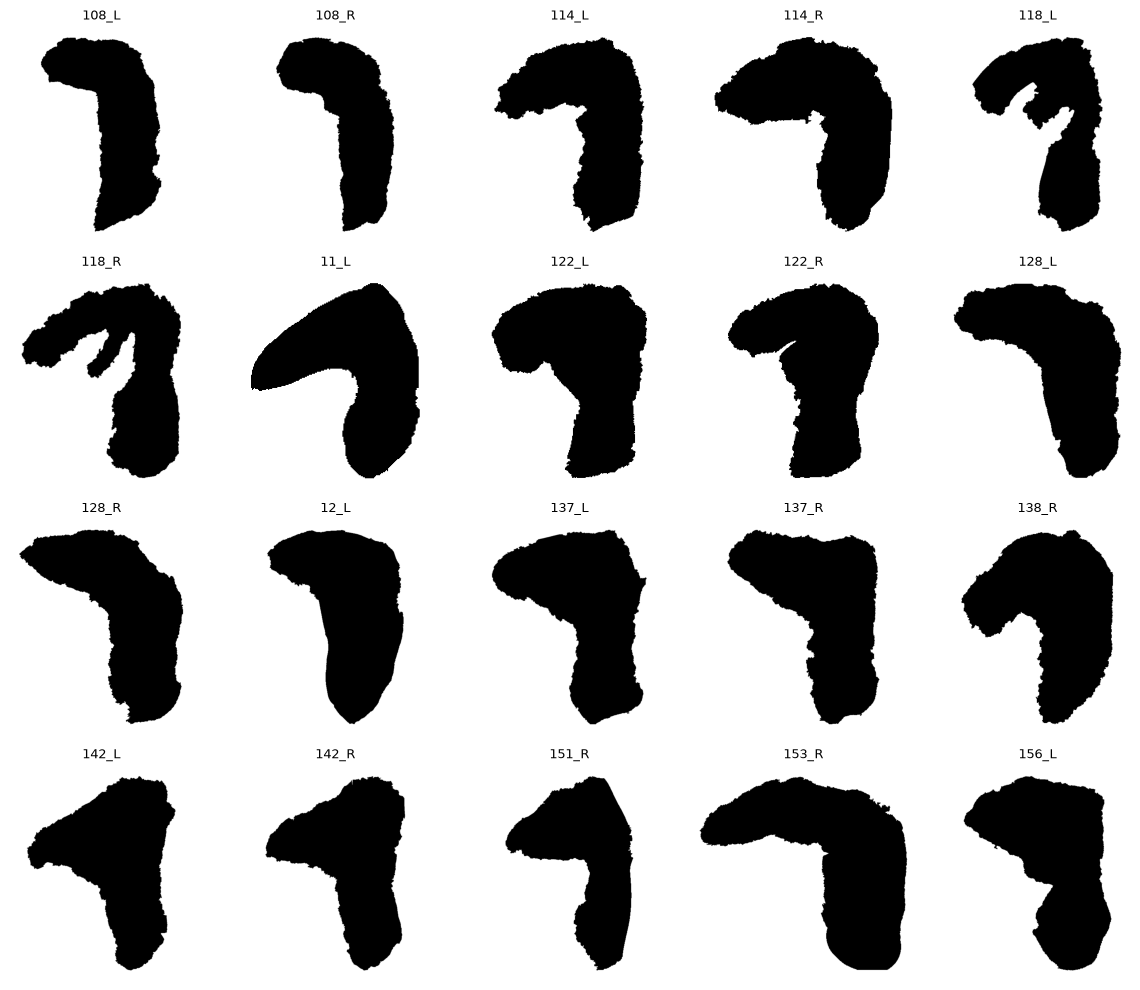

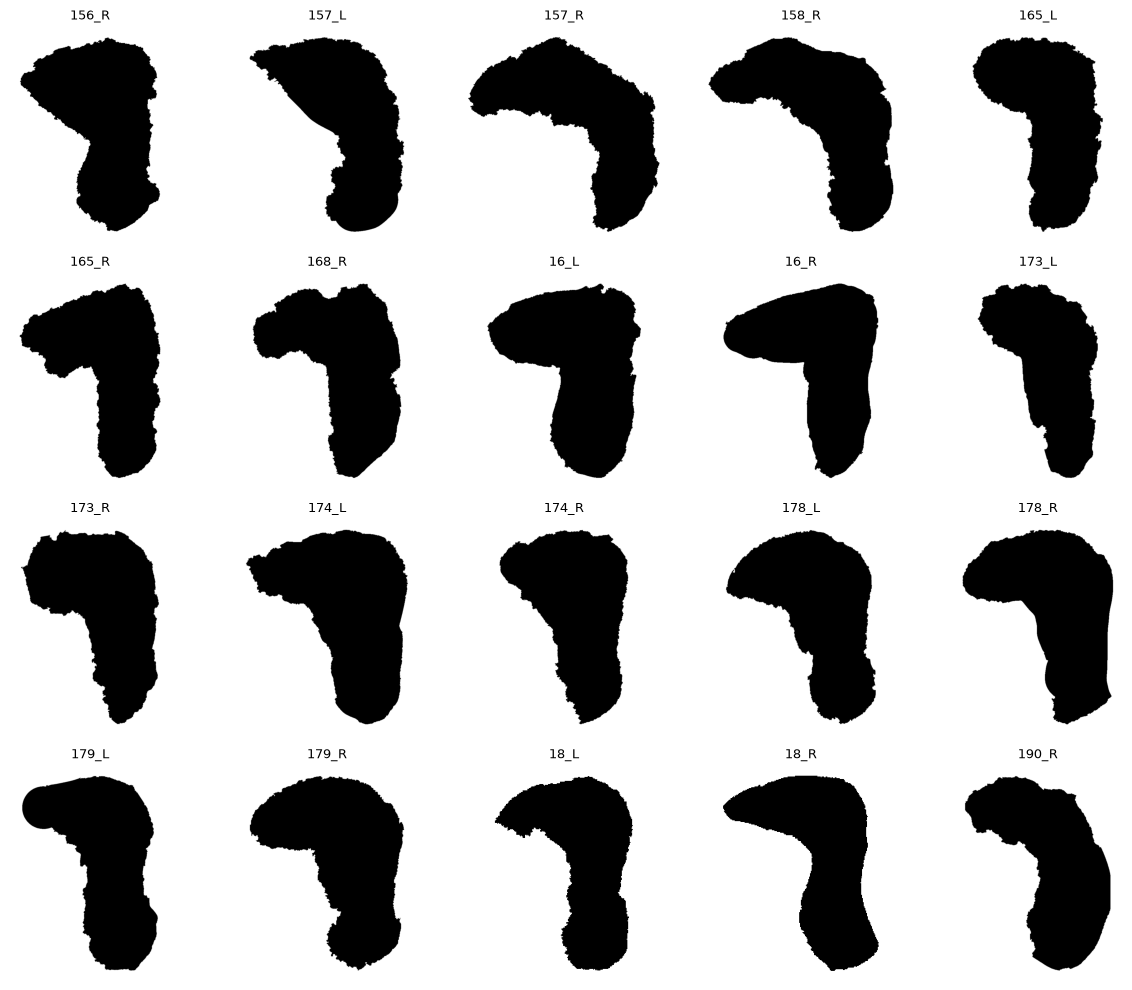

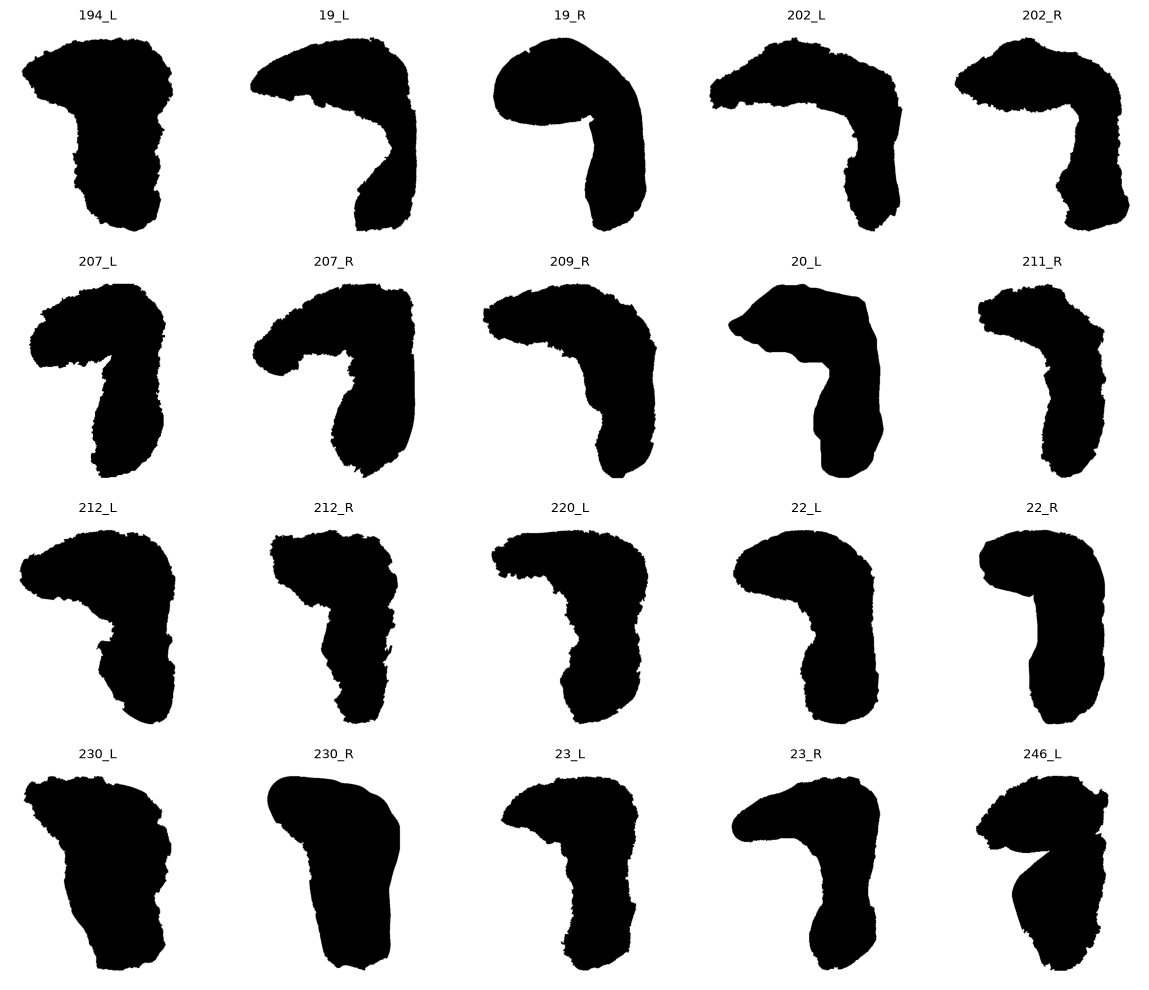

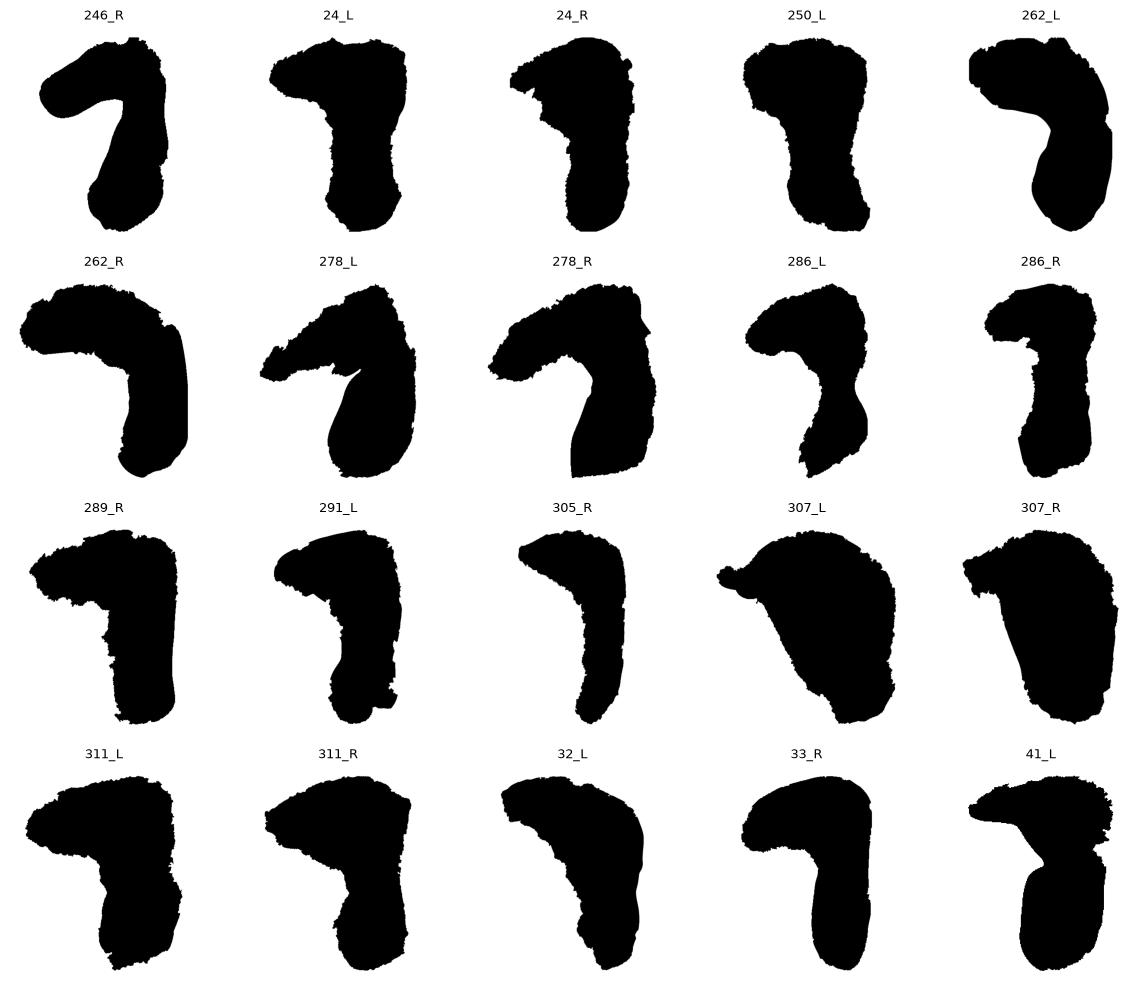

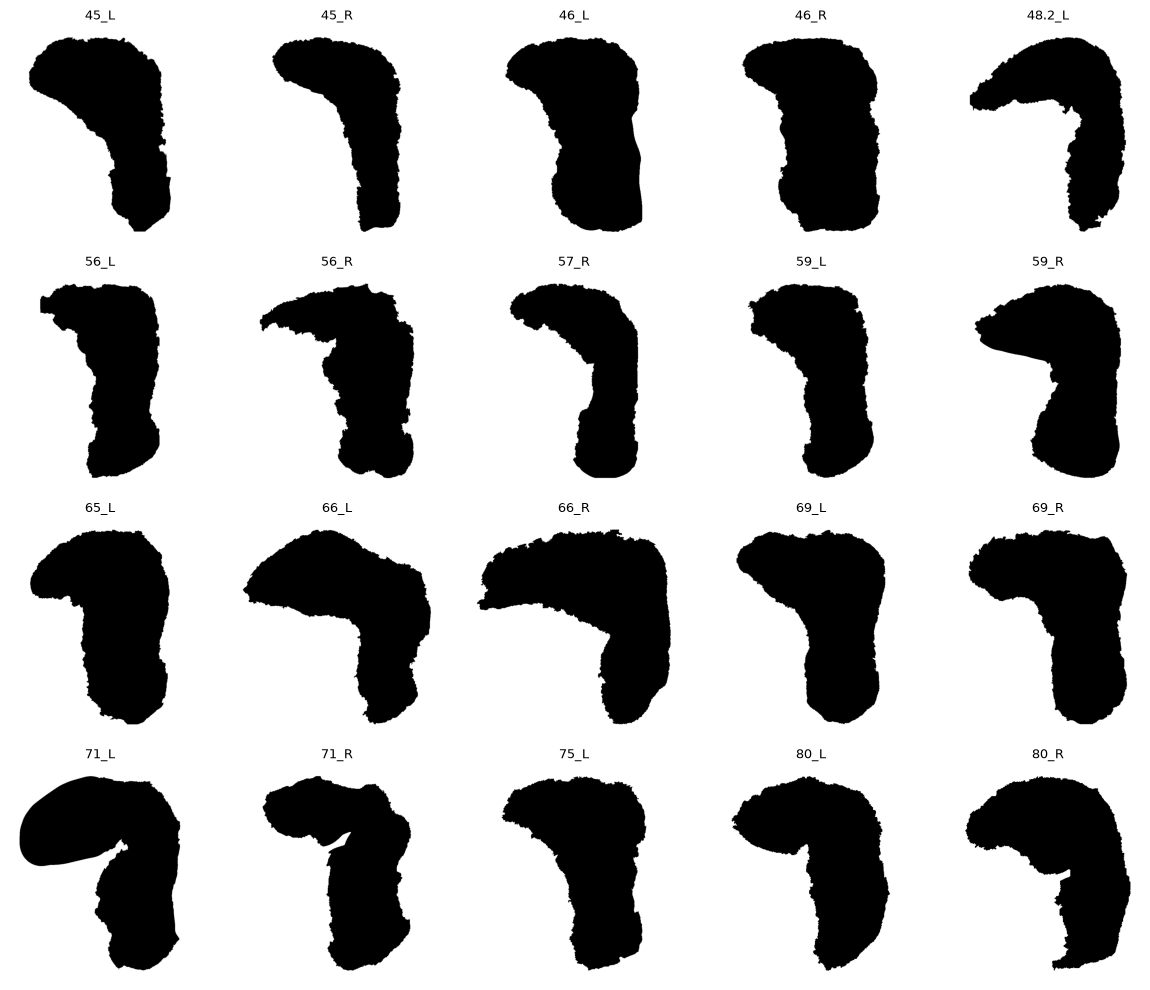

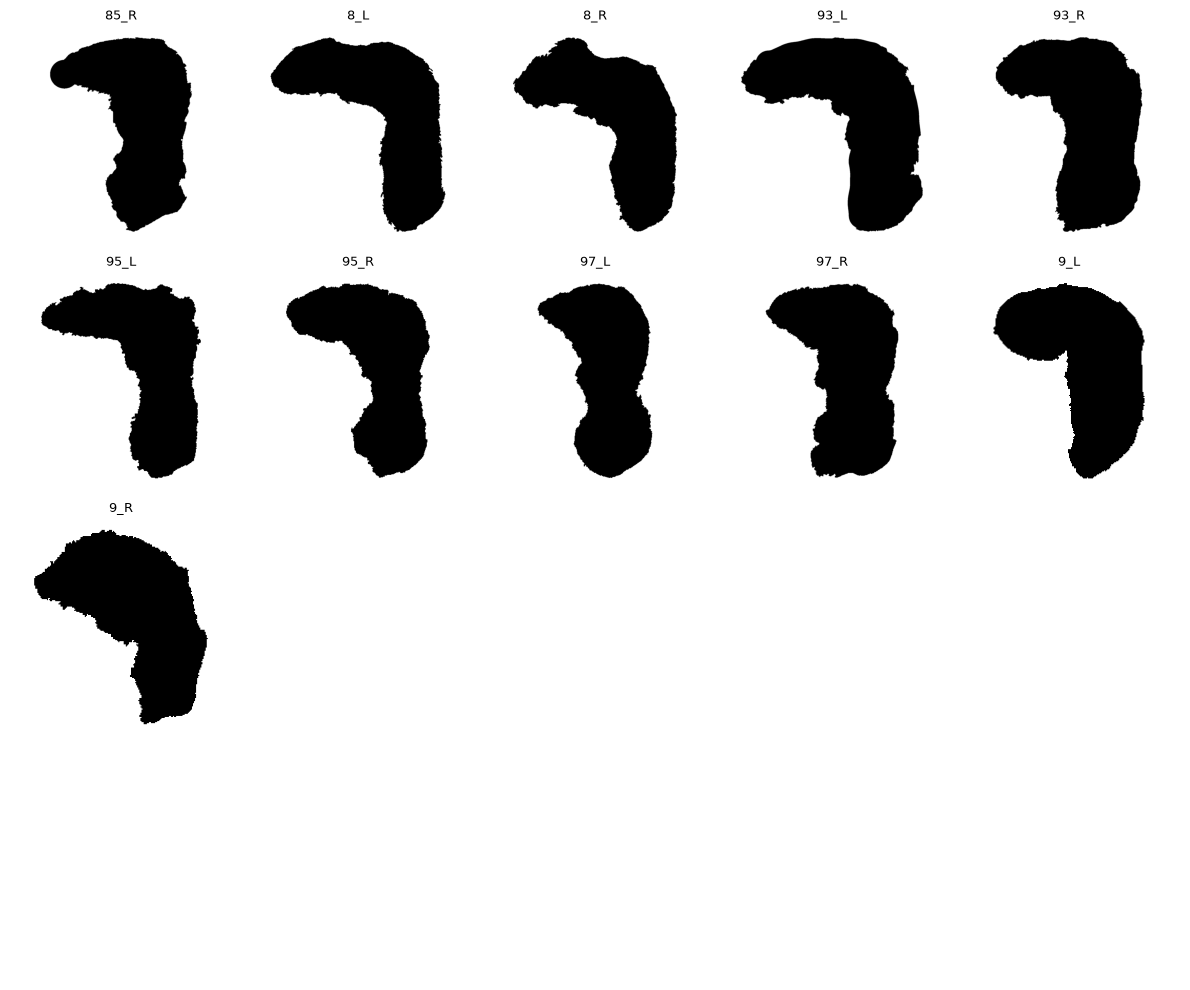

In [4]:
keys=list(cache)
for start in range(0,len(keys),20):
    fig,axes=plt.subplots(4,5,figsize=(12,10))
    for ax in axes.flat:ax.axis('off')
    for ax,key in zip(axes.flat,keys[start:start+20]):ax.imshow(cache[key][0],cmap='gray_r');ax.set_title(key,fontsize=9)
    fig.tight_layout();fig.savefig(OUTPUT/f'contact_sheet_{start//20+1:02d}.png',dpi=150);plt.show()
for key,(mask,pts,raw) in cache.items():
    recon=reconstruct_contour(raw,num_points=N_POINTS)
    recon=recon-recon.mean(0)+pts[:-1].mean(0)
    fig,ax=plt.subplots(figsize=(4,4));ax.plot(pts[:,0],pts[:,1],color='black',label='mask');ax.plot(recon[:,0],recon[:,1],color='tomato',label='Fourier')
    ax.invert_yaxis();ax.set_aspect('equal');ax.set_title(key);ax.legend(fontsize=8)
    fig.savefig(OUTPUT/'reconstruction_qc'/f'{key}.png',dpi=120);plt.close(fig)


In [6]:
#This looks good
# so we can approve the reviewed shapes
APPROVED_REVIEW_FILENAMES = (
    qc.loc[qc["status"].eq("review"), "filename"]
    .drop_duplicates()
    .tolist()
)

print(
    f"Approved {len(APPROVED_REVIEW_FILENAMES)} "
    "visually reviewed masks."
)

display(qc.groupby("status").size().rename("mask_count"))

# Check whether any extraction failures still need attention.
display(
    qc.loc[
        qc["status"].eq("excluded"),
        ["individual_id", "side", "filename", "reason"],
    ]
)

Approved 75 visually reviewed masks.


status
ok        36
review    75
Name: mask_count, dtype: int64

,individual_id,side,filename,reason


## Individual shape analysis
Review flags before approving filenames in configuration. Paired coefficients are averaged only as an exploratory summary; large bilateral distances can indicate true asymmetry, tracing differences or normalization ambiguities. Inspect pairs before interpreting their mean. A unilateral individual contributes one vector. No synthetic copies are analyzed. Dental missingness never excludes an individual from shape analysis.

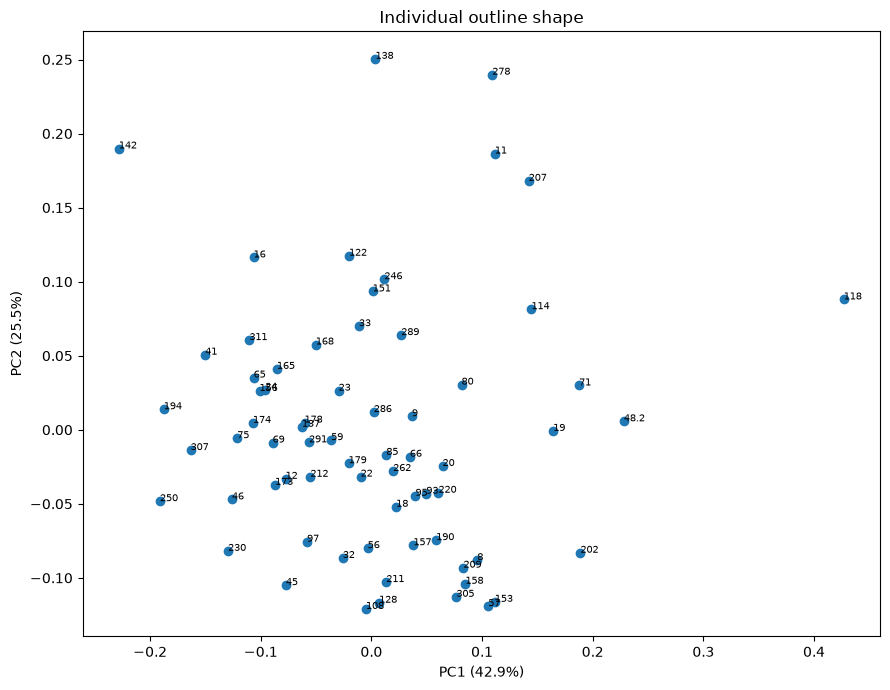

In [7]:
accepted=qc[(qc.status=='ok')|((qc.status=='review') & qc.filename.isin(APPROVED_REVIEW_FILENAMES))][['individual_id','side']]
analysis=descriptors.merge(accepted,on=['individual_id','side'],validate='one_to_one')
features=[c for c in descriptors if c.startswith('efd_')]
assert analysis.individual_id.nunique()>=3,'Need at least three approved individuals'
pairs=[]
for ident,g in analysis.groupby('individual_id'):
    if len(g)==2:pairs.append({'individual_id':ident,'efd_distance':float(np.linalg.norm(g[features].iloc[0]-g[features].iloc[1]))})
pd.DataFrame(pairs,columns=['individual_id','efd_distance']).to_csv(OUTPUT/'bilateral_distances.csv',index=False)
individual=analysis.groupby('individual_id')[features].mean()
individual=individual.sort_index(key=lambda s:pd.to_numeric(s))
x=individual.to_numpy();vary=x.std(0)>1e-12
assert vary.sum()>=2,'Insufficient variation'
pca=PCA(n_components=min(10,len(x)-1,int(vary.sum())),svd_solver='full')
scores=pca.fit_transform(x[:,vary])
result=pd.DataFrame(scores,index=individual.index,columns=[f'PC{j+1}' for j in range(scores.shape[1])])
result['observed_sides_used']=analysis.groupby('individual_id').side.agg(lambda s:''.join(sorted(s)))
result=result.reset_index().merge(metadata,on='individual_id',how='left',validate='one_to_one')
result=result.sort_values('individual_id',key=lambda s:pd.to_numeric(s))
result.to_csv(OUTPUT/'individual_pca_metadata_canines.csv',index=False)
individual.to_csv(OUTPUT/'individual_mean_descriptors.csv')
pd.DataFrame({'PC':range(1,len(pca.explained_variance_ratio_)+1),'variance_fraction':pca.explained_variance_ratio_}).to_csv(OUTPUT/'pca_variance.csv',index=False)
fig,ax=plt.subplots(figsize=(9,7));ax.scatter(scores[:,0],scores[:,1])
for ident,xy in zip(individual.index,scores):ax.annotate(ident,xy[:2],fontsize=7)
ax.set(xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.1%})',ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.1%})',title='Individual outline shape')
fig.tight_layout();fig.savefig(OUTPUT/'individual_pca.png',dpi=180);plt.show()


In [9]:
print(f"Processed mask descriptors: {len(descriptors)}")
print(f"Accepted masks used: {len(analysis)}")
print(f"Individuals analyzed: {len(result)}")

missing_individuals = sorted(
    set(metadata["individual_id"]) - set(result["individual_id"]),
    key=float,
)

print("Individuals not analyzed:", missing_individuals)

Processed mask descriptors: 111
Accepted masks used: 111
Individuals analyzed: 68
Individuals not analyzed: []


## Exploratory clustering (shape only)
K-means forces groups; silhouette scores are not evidence of sexual dimorphism. No automatic choice of two groups. Assess age, preservation, tracing reliability and cluster stability before inference. Fourier harmonics should be chosen using reconstruction checks and sensitivity analysis, not a single clustering score.

In [8]:
z=scores[:,:min(5,scores.shape[1])];comparison=[]
for k in range(2,min(6,len(z)-1)+1):
    model=KMeans(n_clusters=k,random_state=SEED,n_init=30).fit(z)
    if 1<len(set(model.labels_))<len(z):comparison.append({'k':k,'silhouette':silhouette_score(z,model.labels_)})
pd.DataFrame(comparison).to_csv(OUTPUT/'cluster_comparison.csv',index=False);display(pd.DataFrame(comparison))
CHOSEN_K=None
if CHOSEN_K is not None:
    assignment=pd.DataFrame({'individual_id':individual.index,'exploratory_cluster':KMeans(n_clusters=CHOSEN_K,random_state=SEED,n_init=30).fit_predict(z)})
    result.merge(assignment,on='individual_id',validate='one_to_one').to_csv(OUTPUT/'individual_clusters_metadata_canines.csv',index=False)


,k,silhouette
0,2,0.277526
1,3,0.287823
2,4,0.291417
3,5,0.274411
4,6,0.215862


## Canine coverage — no imputation or classifier
Measurements remain in 16 separate columns: BL/MD, crown/cervical, UL/UR/DL/DR. No canine averages, sex classifications or physical units are inferred. All 68 mask individuals have these fields; blanks remain missing. Do not use a model's dental sex prediction as independent ground truth for validating pelvic sex prediction. Screenshot values require source verification before inference.

71 and 173 have exactly the same eight measurements in the screenshot; retained as shown and flagged. No adult-test individuals match the auricular cohort; they are not appended. Individual 7 has dental measurements but no mask in the supplied list and is archived only.

In [ ]:
coverage=metadata[['individual_id','canine_measurement_count','canine_source','canine_review_note']].copy()
coverage.to_csv(OUTPUT/'canine_coverage.csv',index=False)
metadata[['individual_id']+DENTAL].melt(id_vars='individual_id',var_name='measurement',value_name='value').dropna(subset=['value']).to_csv(OUTPUT/'cohort_canine_measurements_long.csv',index=False)
display(coverage[metadata[DENTAL].notna().any(axis=1)])
packages=['numpy','pandas','Pillow','scipy','scikit-learn','scikit-image','matplotlib','pyefd']
settings={'python':platform.python_version(),'versions':{p:version.version(p) for p in packages},'threshold_tolerance':BACKGROUND_TOLERANCE,'harmonics':HARMONICS,'points':N_POINTS,'right_already_reflected':RIGHT_ALREADY_REFLECTED,'approved_review_filenames':APPROVED_REVIEW_FILENAMES}
(OUTPUT/'run_settings.json').write_text(json.dumps(settings,indent=2))
display(pd.Series({'metadata_individuals':len(metadata),'processed_masks':len(descriptors),'accepted_masks':len(analysis),'analyzed_individuals':len(result),'metadata_with_canines':int(metadata[DENTAL].notna().any(axis=1).sum())}))


## Limitations
Absolute size requires photo calibration. Test threshold tolerances and harmonics. Repeat tracing a blinded subset for observer reliability. Future predictive validation must group splits by individual and fit PCA inside training folds. This is not Luna's anatomical-landmark protocol and does not reuse the earlier extrema-based sex formulas.

Methods: Kuhl & Giardina (1982), doi:10.1016/0146-664X(82)90034-X; Luna et al. (2017), doi:10.1002/oa.2604. Software: pyefd and scikit-learn. Inspect reconstructions for normalization ambiguities before interpreting pair means.